# **PROJETO TMBA - Google Play Store App**

### **Projeto desenvolvido por:**
- Débora Jesus, nº2250064
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

### **LLM: DistilBERT**

## **1. Imports and Data Upload**

In [1]:
# Instalação de bibliotecas adicionais
!pip install -q transformers datasets scikit-learn
!pip install datasets
!pip install torchvision

In [2]:
# Imports principais
from google.colab import drive
from google.colab import files
import pandas as pd
import numpy as np
import io

# Pré-processamento e métricas
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix
)

# Hugging Face - tokenização, modelo e treino
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    AutoTokenizer,
    TrainingArguments,
    Trainer
)

# Conversão para dataset compatível com Hugging Face
from datasets import Dataset
import sys
import torch

# Outros imports
import shap
import scipy as sp

In [3]:
# Upload do dataset (em csv)

uploaded = files.upload()

review_df = pd.read_csv(io.BytesIO(uploaded['google_play_store_apps.csv']), sep=',')

Saving google_play_store_apps.csv to google_play_store_apps.csv


In [4]:
review_df.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
4,10 Best Foods for You,Best way,Positive,1.00,0.300000


## **2. Pré-processamento**

In [5]:
# Remover reviews com sentimento neutro
review_df = review_df[review_df['Sentiment'] != 'Neutral']

# Visualizar as primeiras linhas
display(review_df.head(10))

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.000000,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.250000,0.288462
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.400000,0.875000
3,10 Best Foods for You,Best idea us,Positive,1.000000,0.300000
4,10 Best Foods for You,Best way,Positive,1.000000,0.300000
5,10 Best Foods for You,Amazing,Positive,0.600000,0.900000
8,10 Best Foods for You,good you.,Positive,0.700000,0.600000
9,10 Best Foods for You,Useful information The amount spelling errors ...,Positive,0.200000,0.100000
10,10 Best Foods for You,"Thank you! Great app!! Add arthritis, eyes, im...",Positive,0.750000,0.875000
11,10 Best Foods for You,Greatest ever Completely awesome maintain heal...,Positive,0.992188,0.866667


## **3. Fine Tuning**

### **3.1. Codificação dos Rótulos**

In [6]:
# Codificar sentimentos em valores numéricos
le = LabelEncoder()
review_df["label"] = le.fit_transform(review_df["Sentiment"])

# Mostrar primeiras linhas
display(review_df.head(10))

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity,label
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.000000,0.533333,1
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.250000,0.288462,1
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.400000,0.875000,1
3,10 Best Foods for You,Best idea us,Positive,1.000000,0.300000,1
4,10 Best Foods for You,Best way,Positive,1.000000,0.300000,1
5,10 Best Foods for You,Amazing,Positive,0.600000,0.900000,1
8,10 Best Foods for You,good you.,Positive,0.700000,0.600000,1
9,10 Best Foods for You,Useful information The amount spelling errors ...,Positive,0.200000,0.100000,1
10,10 Best Foods for You,"Thank you! Great app!! Add arthritis, eyes, im...",Positive,0.750000,0.875000,1
11,10 Best Foods for You,Greatest ever Completely awesome maintain heal...,Positive,0.992188,0.866667,1


### **3.2. Separação dos Dados em Treino e Teste**

In [7]:
# Separar dados de treino (80%) e teste (20%)
train_df = review_df.sample(frac=0.8, random_state=42)
test_df = review_df.drop(train_df.index)

In [8]:
# Mostrar dimensões dos conjuntos
print("train_df:", train_df.shape)
print("→", train_df.shape[0], "linhas (documentos de treino) e", train_df.shape[1], "colunas (atributos seleccionadas)")

print("\ntest_df:", test_df.shape)
print("→", test_df.shape[0], "linhas (documentos de teste) e", test_df.shape[1], "colunas (atributos seleccionadas)")

train_df: (25815, 6)
→ 25815 linhas (documentos de treino) e 6 colunas (atributos seleccionadas)

test_df: (6454, 6)
→ 6454 linhas (documentos de teste) e 6 colunas (atributos seleccionadas)


### **3.3. Conversão para Dataset Hugging Face**


In [9]:
# Converter DataFrames para Dataset Hugging Face
train_dataset = Dataset.from_pandas(train_df[["Translated_Review", "label"]])
test_dataset = Dataset.from_pandas(test_df[["Translated_Review", "label"]])

In [10]:
# Mostrar o conteúdo
display(train_dataset)
display(test_dataset)

Dataset({
    features: ['Translated_Review', 'label', '__index_level_0__'],
    num_rows: 25815
})

Dataset({
    features: ['Translated_Review', 'label', '__index_level_0__'],
    num_rows: 6454
})

### **3.4. Tokenização dos Conjuntos de Treino e Teste**

In [11]:
# Carregar tokenizador DistilBERT
tokenizer = DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")

# Tokenizar treino
train_encodings = tokenizer(
    list(train_dataset["Translated_Review"]),
    truncation=True,
    padding=True,
    max_length=512
)

# Tokenizar teste
test_encodings = tokenizer(
    list(test_dataset["Translated_Review"]),
    truncation=True,
    padding=True,
    max_length=512
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [12]:
# Adicionar tokens ao treino
train_dataset = train_dataset.add_column("input_ids", train_encodings["input_ids"])
train_dataset = train_dataset.add_column("attention_mask", train_encodings["attention_mask"])

# Adicionar tokens ao teste
test_dataset = test_dataset.add_column("input_ids", test_encodings["input_ids"])
test_dataset = test_dataset.add_column("attention_mask", test_encodings["attention_mask"])

### **3.5. Carregamento do Modelo e Definição dos Parâmetros de Treino**

In [13]:
# Converter datasets para formato PyTorch
train_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
test_dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

# Carregar modelo DistilBERT
model = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

# Definir parâmetros de treino
training_args = TrainingArguments(
    output_dir="./output",
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=2,
    report_to="none"
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### **3.6. Definição da Métrica de Avaliação**


In [14]:
def calcular_metricas(eval_pred):

    logits, labels = eval_pred

    preds = np.argmax(logits, axis=1)

    acc = accuracy_score(labels, preds)
    prec = precision_score(labels, preds, average='weighted')
    rec = recall_score(labels, preds, average='weighted')
    f1 = f1_score(labels, preds, average='weighted')
    kappa = cohen_kappa_score(labels, preds)

    cm = confusion_matrix(labels, preds)

    tn, fp, fn, tp = cm.ravel()

    taxa_erro = (fp + fn) / (tp + tn + fp + fn)

    return {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "kappa": kappa,
        "taxa_erro": taxa_erro
    }

### **3.7. Treino e Avaliação do Modelo**

In [15]:
# Configurar treino
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=calcular_metricas
)

# Treinar modelo
trainer.train()

Step,Training Loss
500,0.460684
1000,0.376153
1500,0.354738
2000,0.329143
2500,0.323698
3000,0.311494
3500,0.290749
4000,0.296565
4500,0.260710
5000,0.236775


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=12908, training_loss=0.2047597736184871, metrics={'train_runtime': 2987.6318, 'train_samples_per_second': 17.281, 'train_steps_per_second': 4.32, 'total_flos': 6839291792609280.0, 'train_loss': 0.2047597736184871, 'epoch': 2.0})

In [16]:
# Avaliar modelo
resultados = trainer.evaluate()

# Converter resultados para DataFrame
df_resultados = pd.DataFrame([{
    "Model": "DistilBERT",
    "Acc": resultados["eval_accuracy"],
    "Prec": resultados["eval_precision"],
    "Rec": resultados["eval_recall"],
    "F1": resultados["eval_f1"],
    "Kappa": resultados["eval_kappa"],
    "Taxa_Erro": resultados["eval_taxa_erro"]
}])

# Mostrar tabela
print(df_resultados)

# Exportar CSV
df_resultados.to_csv("DistilBERT_results.csv", index=False)

        Model       Acc      Prec       Rec        F1     Kappa  Taxa_Erro
0  DistilBERT  0.964208  0.964663  0.964208  0.964371  0.906937   0.035792


## **4. Predição de Novo Comentário**

In [17]:
### --- NOVOS COMENTÁRIOS: --- ###

uploaded = files.upload()

novos_comentarios = pd.read_csv(io.BytesIO(uploaded['Comentarios.csv']), sep=';')

Saving Comentarios.csv to Comentarios.csv


### **4.1. Pré- processamento**

In [18]:
# Remover reviews com sentimento neutro
novos_comentarios = novos_comentarios[novos_comentarios['Sentiment'] != 'Neutral']

# Visualizar as primeiras linhas
display(novos_comentarios.head(10))

,Comentarios_Novos,Sentiment
0,This app is a true paragon.,Positive
1,The interface remains totally execrable.,Negative
3,Simply effulgent and highly efficient!,Positive
4,Navigation is inimical to usage.,Negative


### **4.2. Avaliação de Novos Comentários**

In [19]:
# Extrair textos
textos = novos_comentarios["Comentarios_Novos"].astype(str).tolist()

# Tokenizar em batch
tokens = tokenizer(
    textos,
    truncation=True,
    padding=True,
    max_length=128,
    return_tensors="pt"
)

# Garantir que o modelo está na GPU (se existir)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Enviar tokens para o mesmo device
tokens = {k: v.to(device) for k, v in tokens.items()}

# Colocar modelo em modo avaliação
model.eval()

# Inferência
with torch.no_grad():
    outputs = model(**tokens)

logits = outputs.logits

# Previsões
classe_prevista = np.argmax(logits.cpu().numpy(), axis=1)

# Converter para labels originais
sentimento = le.inverse_transform(classe_prevista)

# Guardar no dataframe
novos_comentarios["Sentimento_previsto"] = sentimento

# Mostrar resultados
print(novos_comentarios[["Comentarios_Novos", "Sentiment", "Sentimento_previsto"]])

                          Comentarios_Novos Sentiment Sentimento_previsto
0               This app is a true paragon.  Positive            Positive
1  The interface remains totally execrable.  Negative            Negative
3    Simply effulgent and highly efficient!  Positive            Positive
4          Navigation is inimical to usage.  Negative            Negative


## **5. eXplainable AI**

In [20]:
!pip install shap -q

A calcular SHAP values globais para o DistilBERT...


PartitionExplainer explainer:  75%|███████▌  | 3/4 [00:16<00:02,  2.33s/it]

  0%|          | 0/110 [00:00<?, ?it/s]

PartitionExplainer explainer: 100%|██████████| 4/4 [00:22<00:00,  3.79s/it]

  0%|          | 0/90 [00:00<?, ?it/s]

PartitionExplainer explainer: 5it [00:27,  6.89s/it]


A gerar gráfico global SHAP...


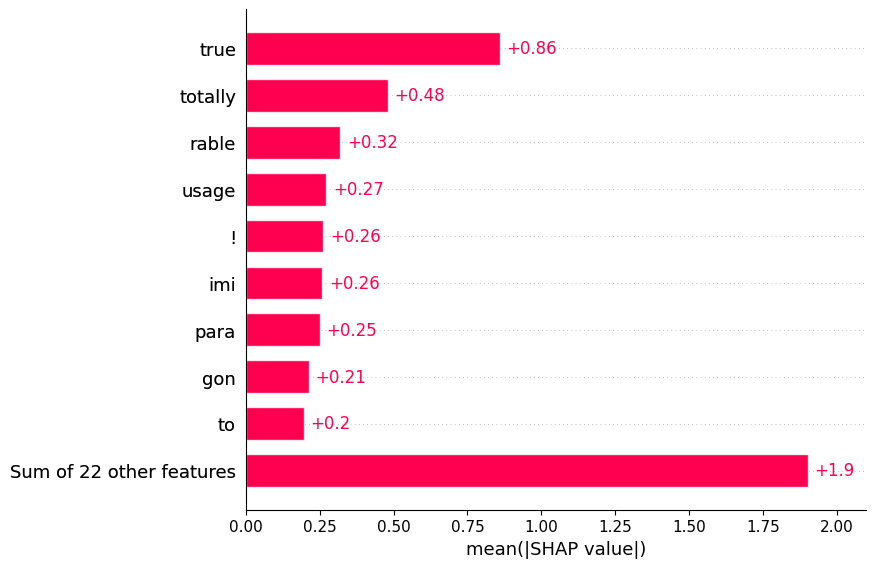

In [26]:
# ==========================================================
# EXPLAINABLE AI - SHAP PARA DISTILBERT (VERSÃO ULTRA-BLINDADA)
# ==========================================================

# 1. Mover o modelo para o CPU (evita estouro de memória no Colab com o SHAP)
device = torch.device("cpu")
model.to(device)
model.eval()

# 2. Função de previsão robusta que força a conversão para lista de strings
def predict_probabilities(texts):

    if isinstance(texts, np.ndarray):
        texts = texts.tolist()
    if isinstance(texts, str):
        texts = [texts]

    cleaned_texts = [str(t) for t in texts]

    inputs = tokenizer(
        cleaned_texts,
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.nn.functional.softmax(outputs.logits, dim=-1)
    return probabilities.cpu().numpy()

# 3. Inicializar o Explainer específico para Texto com a função robusta
explainer = shap.Explainer(predict_probabilities, masker=shap.maskers.Text(tokenizer))

# 4. Preparar estritamente a amostra de strings
text_samples = [str(t) for t in textos if pd.notna(t)]
text_samples = [t for t in text_samples if t.strip() != ""]

# Selecionamos apenas as primeiras 15 para testar rápido (SHAP em LLMs demora)
text_samples = text_samples[:15]

print("A calcular SHAP values globais para o DistilBERT...")
shap_values = explainer(text_samples)

# 5. Gerar o gráfico global de barras
print("A gerar gráfico global SHAP...")
shap.plots.bar(shap_values[:, :, 1])

In [29]:
# ==========================================================
# TOP FEATURES MAIS IMPORTANTES - DISTILBERT (CORREÇÃO DE ÍNDICE)
# ==========================================================

all_tokens_data = []

# 1. Percorrer cada frase explicada para extrair os dados individualmente
for idx in range(len(shap_values)):

    frase_tokens = shap_values.feature_names[idx]

    valores_frase_completa = shap_values.values[idx]

    if valores_frase_completa.ndim == 2:
        frase_valores = valores_frase_completa[:, 1]
    else:
        frase_valores = valores_frase_completa

    # Guardar os pares (token, valor absoluto)
    for token, val in zip(frase_tokens, frase_valores):
        token_clean = str(token).strip()

        if token_clean not in ['', '[PAD]', '[CLS]', '[SEP]', '##', 'None']:
            all_tokens_data.append({
                'feature': token_clean,
                'importance': np.abs(val)
            })

# 2. Criar o DataFrame com todos os tokens agregados
df_raw_importance = pd.DataFrame(all_tokens_data)

# 3. Agrupar por palavra/token e calcular a média real
importance_df = df_raw_importance.groupby('feature', as_index=False).mean()

# 4. Ordenar do maior impacto para o menor
importance_df = importance_df.sort_values(
    by='importance',
    ascending=False
)

print("\nTop 20 tokens/palavras mais importantes para o DistilBERT:\n")
print(importance_df.head(20).to_string(index=False))


Top 20 tokens/palavras mais importantes para o DistilBERT:

  feature  importance
     true    0.860624
  totally    0.479737
    rable    0.319677
    usage    0.272349
        !    0.261973
      imi    0.258589
     para    0.250290
      gon    0.212532
       to    0.197208
       ex    0.187751
        e    0.169227
efficient    0.164921
   highly    0.161872
       in    0.153893
      cal    0.150932
       ul    0.143785
       ff    0.138428
interface    0.096050
        a    0.085210
       is    0.081920


In [ ]:
# ==========================================================
#  GUARDAR RESULTADOS - DISTILBERT
# ==========================================================

importance_df.to_csv(
    "distilbert_shap_feature_importance.csv",
    index=False
)

print("Ficheiro guardado:")
print("distilbert_shap_feature_importance.csv")


 A ANALISAR: "great finding place take right door step place want go worked great warsaw aire"


  0%|          | 0/272 [00:00<?, ?it/s]


A gerar explicação SHAP...



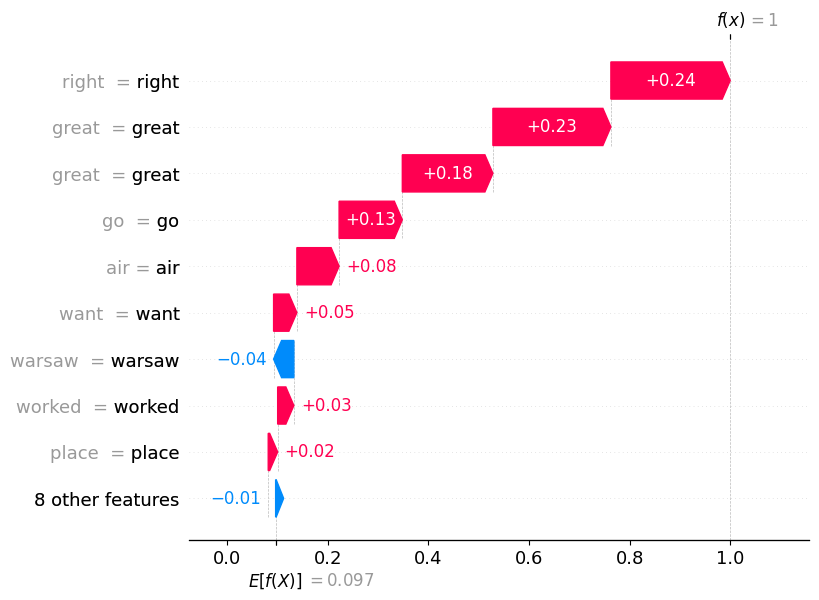


TOP TOKENS MAIS IMPORTANTES:

'right' ---> impacto SHAP = 0.2372
'great' ---> impacto SHAP = 0.2345
'great' ---> impacto SHAP = 0.1800
'go' ---> impacto SHAP = 0.1256
'air' ---> impacto SHAP = 0.0839
'want' ---> impacto SHAP = 0.0463
'warsaw' ---> impacto SHAP = -0.0403
'worked' ---> impacto SHAP = 0.0322
'place' ---> impacto SHAP = 0.0188
'e' ---> impacto SHAP = 0.0052

EXPLICAÇÃO AUTOMÁTICA:

O token 'right' teve influência POSITIVA na classificação.
O token 'great' teve influência POSITIVA na classificação.
O token 'great' teve influência POSITIVA na classificação.
O token 'go' teve influência POSITIVA na classificação.
O token 'air' teve influência POSITIVA na classificação.
O token 'want' teve influência POSITIVA na classificação.
O token 'warsaw' teve influência NEGATIVA na classificação.
O token 'worked' teve influência POSITIVA na classificação.
O token 'place' teve influência POSITIVA na classificação.
O token 'e' teve influência POSITIVA na classificação.

 A ANALISAR: "trac

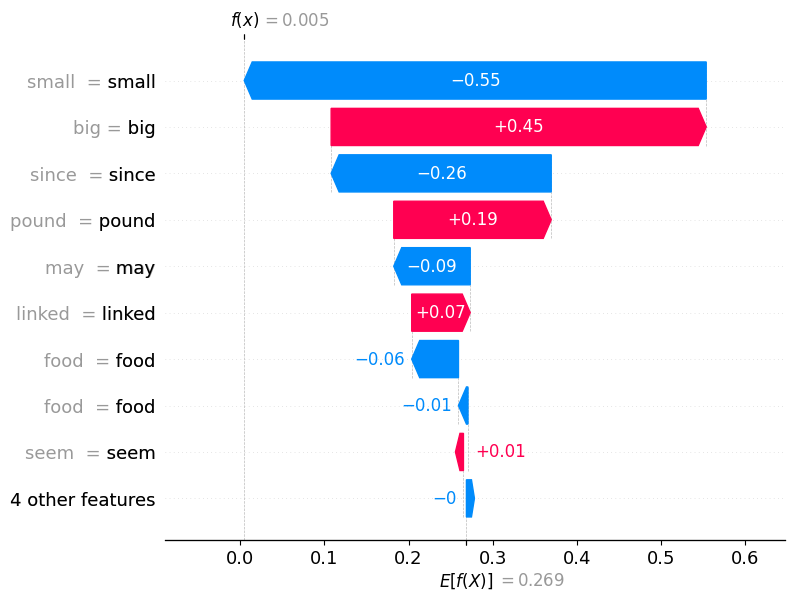


TOP TOKENS MAIS IMPORTANTES:

'small' ---> impacto SHAP = -0.5486
'big' ---> impacto SHAP = 0.4454
'since' ---> impacto SHAP = -0.2614
'pound' ---> impacto SHAP = 0.1870
'may' ---> impacto SHAP = -0.0908
'linked' ---> impacto SHAP = 0.0695
'food' ---> impacto SHAP = -0.0555
'food' ---> impacto SHAP = -0.0113
'seem' ---> impacto SHAP = 0.0054
'fitness' ---> impacto SHAP = -0.0049

EXPLICAÇÃO AUTOMÁTICA:

O token 'small' teve influência NEGATIVA na classificação.
O token 'big' teve influência POSITIVA na classificação.
O token 'since' teve influência NEGATIVA na classificação.
O token 'pound' teve influência POSITIVA na classificação.
O token 'may' teve influência NEGATIVA na classificação.
O token 'linked' teve influência POSITIVA na classificação.
O token 'food' teve influência NEGATIVA na classificação.
O token 'food' teve influência NEGATIVA na classificação.
O token 'seem' teve influência POSITIVA na classificação.
O token 'fitness' teve influência NEGATIVA na classificação.

 A AN

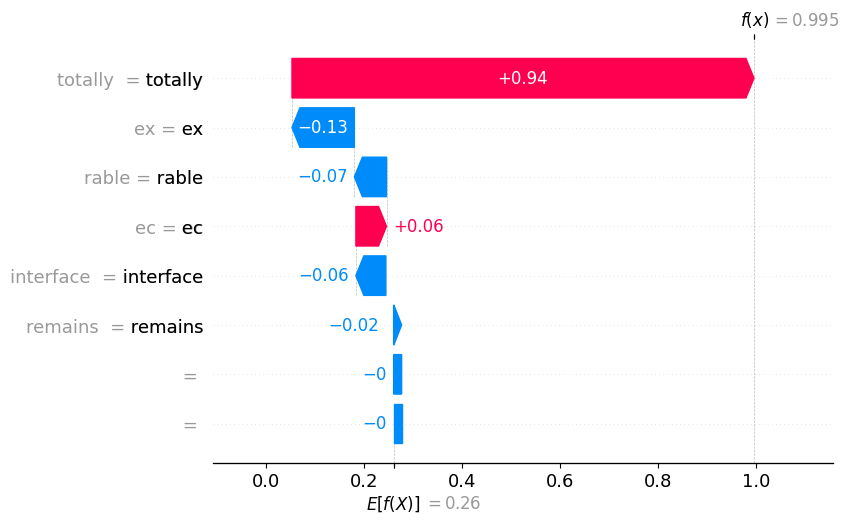


TOP TOKENS MAIS IMPORTANTES:

'totally' ---> impacto SHAP = 0.9421
'ex' ---> impacto SHAP = -0.1273
'rable' ---> impacto SHAP = -0.0655
'ec' ---> impacto SHAP = 0.0624
'interface' ---> impacto SHAP = -0.0612
'remains' ---> impacto SHAP = -0.0158

EXPLICAÇÃO AUTOMÁTICA:

O token 'totally' teve influência POSITIVA na classificação.
O token 'ex' teve influência NEGATIVA na classificação.
O token 'rable' teve influência NEGATIVA na classificação.
O token 'ec' teve influência POSITIVA na classificação.
O token 'interface' teve influência NEGATIVA na classificação.
O token 'remains' teve influência NEGATIVA na classificação.


In [30]:
# ==========================================================
# Comentário positivo e negativo do df_final e comentário extraído do CSV
# ==========================================================

texto_positivo = "great finding place take right door step place want go worked great warsaw aire"
texto_negativo = "track food linked since fitness food pound may seem small big"
texto_novo     = "interface remains totally execrable"

todas_as_frases = [texto_positivo, texto_negativo, texto_novo]

# ==========================================================
# O LOOP QUE ANALISA AS 3 FRASES AUTOMATICAMENTE - DISTILBERT
# ==========================================================

for frase_escolhida in todas_as_frases:
    print("\n" + "="*70)
    print(f" A ANALISAR: \"{frase_escolhida}\"")
    print("="*70)

    # ==========================================================
    # CALCULAR SHAP VALUES
    # ==========================================================
    shap_explanation = explainer([frase_escolhida])

    shap_values_for_plot = shap_explanation[0, :, 1]

    # ==========================================================
    # GERAR EXPLICAÇÃO VISUAL
    # ==========================================================
    print("\nA gerar explicação SHAP...\n")

    shap.plots.waterfall(shap_values_for_plot)

    # ==========================================================
    # MOSTRAR PALAVRAS MAIS IMPORTANTES
    # ==========================================================
    feature_names = shap_values_for_plot.feature_names
    valores = shap_values_for_plot.values

    indices = np.argsort(np.abs(valores))[::-1]

    print("\nTOP TOKENS MAIS IMPORTANTES:\n")

    for i in indices[:10]:
        if valores[i] != 0:
            palavra = str(feature_names[i]).strip()
            impacto = valores[i]

            # Evitar poluir o terminal com tokens vazios ou de preenchimento
            if palavra not in ['', '[PAD]', '[CLS]', '[SEP]', '##', 'None']:
                print(f"'{palavra}' ---> impacto SHAP = {impacto:.4f}")

    # ==========================================================
    # EXPLICAÇÃO TEXTUAL AUTOMÁTICA
    # ==========================================================
    print("\nEXPLICAÇÃO AUTOMÁTICA:\n")

    for i in indices[:10]:
        if valores[i] != 0:
            palavra = str(feature_names[i]).strip()
            impacto = valores[i]

            if palavra not in ['', '[PAD]', '[CLS]', '[SEP]', '##', 'None']:
                if impacto > 0:
                    direcao = "POSITIVA"
                else:
                    direcao = "NEGATIVA"

                print(
                    f"O token '{palavra}' "
                    f"teve influência {direcao} "
                    f"na classificação."
                )